# Exercise 08 — Decoding Strategies

A language model gives you a probability distribution over the next token. A **decoding strategy** decides what to do with it: take the most likely token, keep several candidates, or roll the dice. The same model can write a dull loop, a fluent paragraph or nonsense, depending only on this choice.

In this notebook you compare the classic strategies on GPT-2: **greedy search**, **beam search**, and **sampling** with **temperature**, **top-k** and **top-p**. You look at what they produce, but you also *measure* it: how likely is the text according to the model, and how repetitive is it? Along the way you reproduce a famous figure that explains why the most likely text is not the best text.

**🙏 Acknowledgment:** This notebook draws inspiration, explanations and graphics from the excellent Hugging Face blog post [*How to generate text*](https://huggingface.co/blog/how-to-generate) by [Patrick von Platen](https://huggingface.co/patrickvonplaten). Huge thanks to the author and the Hugging Face team for their open resources 💙🤗

## What you will do
1. **Measuring a generation**: the log-probability of a text, and how repetitive it is.
2. **Greedy search**: the most likely token at every step.
3. **Beam search**: several candidates at once.
4. **N-gram penalties**: a quick fix for repetition, and where it breaks.
5. **Is the most likely text the best text?** Human text versus beam search.
6. **Sampling**: pure sampling, temperature, top-k and top-p.
7. **All strategies side by side**: the trade-off between likely and diverse text.
8. **Multiple-choice questions**: to check your understanding.

## How to work through it
- Run the cells **in order** and fill in **every `# TODO`**.
- Tasks are numbered (**1.1**, **1.2**, …). Tasks that say *Your answer here* want a short written answer, not code.
- Most implementation tasks are followed by a **✅ Check** cell that verifies your work automatically.

> **Heads up:** this notebook uses GPT-2 (~550 MB, cached from week 6 and notebook 0). Everything runs on a CPU. The comparison in Part 7 generates 25 texts and takes one to two minutes.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

MODEL_NAME = "openai-community/gpt2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)
model.eval()
model.generation_config.pad_token_id = tokenizer.eos_token_id  # GPT-2 has no padding token (see notebook 0)

Using mps device


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Two helpers, as in notebook 0: `generate_ids` returns the token ids of the prompt and of the continuation, and `show` prints the text.

In [2]:
def generate_ids(prompt, **generate_kwargs):
    # The prompt's token ids and the new token ids of one continuation, as two 1-D tensors
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    outputs = model.generate(**inputs, **generate_kwargs)
    prompt_ids = inputs["input_ids"][0]
    return prompt_ids, outputs[0, len(prompt_ids):]


def show(prompt_ids, new_ids):
    print(tokenizer.decode(prompt_ids) + "|" + tokenizer.decode(new_ids))


PROMPT = "I enjoy walking with my cute dog"

## 1. Measuring a generation

Judging texts by eye is useful, but slow and subjective. Two simple numbers help us compare strategies:

- **How likely is the text according to the model?** The log-probability of every generated token, given everything before it. We report the **average per token**, so that texts of different lengths can be compared. (This is the negative of the loss you trained the mini GPT with, and $e^{-\text{average}}$ is the perplexity from week 3.)
- **How repetitive is it?** **Distinct-n** ([Li et al., 2016](https://arxiv.org/abs/1510.03055)) is the number of *different* n-grams in a text divided by the number of n-grams. A text without any repeated n-gram has a distinct-n of 1; a text that keeps repeating the same phrase gets close to 0.

**1.1 Complete `token_log_probs`**, which returns the log-probability of every token of a continuation, given the prompt and the tokens before it.

Hints:
- Concatenate the prompt and the continuation and run the model **once** on the whole sequence (no need for `generate`).
- The logits at position $i$ predict the token at position $i + 1$ (as in week 6). The first continuation token is predicted at the *last prompt position*.
- `F.log_softmax(logits, dim=-1)` turns logits into log-probabilities, and `tensor.gather(-1, index)` picks one entry per row.

In [3]:
@torch.no_grad()
def token_log_probs(prompt_ids, new_ids):
    # The log-probability of every token in new_ids given the prompt and the earlier new tokens, shape (len(new_ids),)
    ids = torch.cat([prompt_ids, new_ids]).unsqueeze(0)  # (1, prompt_length + new_length)
    logits = model(ids).logits[0]
    log_probs = F.log_softmax(logits[len(prompt_ids) - 1 : -1], dim=-1)
    return log_probs.gather(-1, new_ids.unsqueeze(-1)).squeeze(-1)

In [4]:
# ✅ Check token_log_probs against the scores that generate reports itself
inputs = tokenizer(PROMPT, return_tensors="pt").to(device)
out = model.generate(**inputs, max_new_tokens=10, return_dict_in_generate=True, output_scores=True)
expected = model.compute_transition_scores(out.sequences, out.scores, normalize_logits=True)[0]
mine = token_log_probs(inputs["input_ids"][0], out.sequences[0, inputs["input_ids"].shape[1]:])
assert mine.shape == (10,), f"expected one log-probability per new token, got shape {tuple(mine.shape)}"
assert torch.allclose(mine, expected, atol=1e-3), f"expected {expected}, got {mine}"
print("Looks good ✅")

Looks good ✅


**1.2 Complete `distinct_n`.** Split the text into words at whitespace.

In [5]:
def distinct_n(text, n):
    # The number of different word n-grams divided by the number of word n-grams (1.0 for texts with fewer than n words)
    words = text.split()
    ngrams = [tuple(words[i : i + n]) for i in range(len(words) - n + 1)]
    if not ngrams:
        return 1.0
    return len(set(ngrams)) / len(ngrams)

In [6]:
# ✅ Check distinct_n
assert distinct_n("the cat sat on the mat", 1) == 5 / 6, "'the' occurs twice, so 5 of the 6 words are different"
assert distinct_n("the cat the cat", 2) == 2 / 3, "the bigrams are (the, cat), (cat, the), (the, cat)"
assert distinct_n("a b c d", 2) == 1.0
assert distinct_n("hello", 2) == 1.0, "a text with fewer than n words has no n-grams"
print("Looks good ✅")

Looks good ✅


From now on, `report` prints a continuation together with both numbers:

In [7]:
def report(prompt_ids, new_ids):
    show(prompt_ids, new_ids)
    avg = token_log_probs(prompt_ids, new_ids).mean().item()
    print(f"-> average log-prob per token {avg:.2f}, distinct-2 {distinct_n(tokenizer.decode(new_ids), 2):.2f}")

## 2. Greedy search

Greedy search selects the token with the **highest conditional probability** at every step:

$$w_t = \arg\max_{w} P(w \mid w_{1:t-1})$$

<center><img src="./assets/greedy_search.png"/></center>

Starting from the word **"The"**, the algorithm greedily chooses the next word with the highest probability at each step:

| Step | Current sequence | Next word (highest probability) | Resulting sequence |
|------|------------------|----------------------------------|--------------------|
| 1 | "The" | "nice" (0.5) | "The nice" |
| 2 | "The nice" | "woman" (0.4) | "The nice woman" |

The probability of the final sequence is $0.5 \times 0.4 = 0.2$.

Greedy search is the default of `generate`:

In [8]:
greedy = generate_ids(PROMPT, max_new_tokens=40)
report(*greedy)

I enjoy walking with my cute dog|, but I'm not sure if I'll ever be able to walk with my dog. I'm not sure if I'll ever be able to walk with my dog.

I'm not sure
-> average log-prob per token -1.00, distinct-2 0.50


**2.1 What are your thoughts on greedy search?** What is wrong with the generation above, and what limitations does the method have? Look at the tree in the figure: is there a sequence of two words with a higher probability than *The nice woman*?

---

*Answer:*

Greedy search is **simple and fast** (one forward pass per token, no choices to tune) and deterministic, which is useful when you want the model's single best guess, for example for a short answer or a classification-like task.

Its limitations:
- **Repetition**: the generation above keeps repeating the same sentence. Once a phrase is in the context, repeating it is very likely, and greedy search cannot escape the loop.
- **Shortsightedness**: it only looks one step ahead. In the tree, *The dog has* has probability $0.4 \times 0.9 = 0.36$, much more than *The nice woman* ($0.2$), but greedy search never considers it, because "dog" (0.4) was not the most likely word at step 1. The high-probability word "has" is hidden behind a lower-probability word.
- So the result is **not the most likely sequence**, and also not a very interesting one.

---

## 3. Beam search

**Beam search** keeps the `num_beams` most likely *sequences* (the **beams**) at every step, instead of a single one, and in the end returns the most likely of them. It reduces the risk of missing a likely sequence whose start looks less likely.

### How it works
1. Start with the prompt as the only beam.
2. Extend every beam with every possible next token and compute the probability of each extended sequence (the product of its token probabilities, or the sum of the log-probabilities).
3. Keep only the `num_beams` most likely extended sequences.
4. Repeat until the beams end (EOS or the length limit), and return the most likely one.

<center><img src="./assets/beam_search.png"/></center>

With `num_beams=2`, starting from **"The"**:

| Step | Candidates | Beams kept |
|------|------------|------------|
| 1 | "The nice" (0.5), "The dog" (0.4), "The car" (0.1) | "The nice" (0.5), "The dog" (0.4) |
| 2 | "The nice woman" (0.5 × 0.4 = 0.20), "The nice house" (0.15), "The nice guy" (0.15), "The dog has" (0.4 × 0.9 = 0.36), "The dog runs" (0.02), "The dog and" (0.02) | "The dog has" (0.36), "The nice woman" (0.20) |

The result is **"The dog has"**, which greedy search missed.

**3.1 Work it out by hand.** Suppose the tree went one step further, and the most likely third words were *"a"* after *The dog has* with probability 0.4, and *"smiled"* after *The nice woman* with probability 0.95. Which sequence would greedy search and which would beam search (2 beams) return after three steps, and with which probability?

In [9]:
p_greedy = 0.5 * 0.4 * 0.95  # The nice woman smiled
p_beam = 0.5 * 0.4 * 0.95    # The nice woman smiled (0.19) now beats The dog has a (0.4 * 0.9 * 0.4 = 0.144)

In [10]:
# ✅ Check your numbers
assert abs(p_greedy - 0.19) < 1e-9, "greedy search follows nice -> woman -> smiled"
assert abs(p_beam - 0.19) < 1e-9, "both beams survive to step 3. Compute the probability of The dog has a and of The nice woman smiled"
print("Looks good ✅  Beam search kept The nice woman as its second beam, and at step 3 it overtook The dog has: a lead at one step can disappear at the next.")

Looks good ✅  Beam search kept The nice woman as its second beam, and at step 3 it overtook The dog has: a lead at one step can disappear at the next.


Now on GPT-2. `num_beams` activates beam search. With `num_return_sequences` you get several of the final beams (at most `num_beams`), and `sequences_scores` holds their scores: the sum of the log-probabilities divided by the length of the sequence (controlled by the `length_penalty` argument; question 3.3 asks why).

**3.2 Run beam search with 5 beams** and return all 5 final beams with their scores. Set `early_stopping=True`, so that the search ends as soon as `num_beams` finished candidates exist.

In [11]:
inputs = tokenizer(PROMPT, return_tensors="pt").to(device)
beam_out = model.generate(
    **inputs, max_new_tokens=40, num_beams=5, early_stopping=True,
    num_return_sequences=5, return_dict_in_generate=True, output_scores=True,
)

prompt_ids = inputs["input_ids"][0]
for sequence, score in zip(beam_out.sequences, beam_out.sequences_scores):
    print(f"score {score:.3f}: {tokenizer.decode(sequence[len(prompt_ids):])!r}\n")

score -0.925: ", but I'm not sure if I'll ever be able to walk with him again.\n\nI'm not sure if I'll ever be able to walk with him again. I'm not sure"

score -0.948: ", but I'm not sure if I'll ever be able to walk with him again.\n\nI'm not sure if I'll ever be able to walk with him again.\n\nI'm"

score -0.953: ", but I'm not sure if I'll ever be able to walk with him again.\n\nI'm not sure if I'll ever be able to walk with him again. I don't know"

score -0.976: ", but I'm not sure if I'll ever be able to walk with him again.\n\nI'm not sure if I'll ever be able to walk with him again. I don't think"

score -0.978: ", but I'm not sure if I'll ever be able to walk with him again.\n\nI'm not sure if I'll ever be able to walk with him again. I don't have"



In [12]:
# ✅ Check your beams
assert beam_out.sequences.shape[0] == 5, "return all 5 beams"
assert beam_out.sequences_scores is not None, "pass output_scores=True and return_dict_in_generate=True to get the scores"
assert (beam_out.sequences_scores[:-1] >= beam_out.sequences_scores[1:]).all(), "the beams come sorted by score"
print("Looks good ✅")

Looks good ✅


In [13]:
beam = (prompt_ids, beam_out.sequences[0, len(prompt_ids):])
print("===== greedy =====")
report(*greedy)
print("\n===== beam search, 5 beams =====")
report(*beam)

===== greedy =====
I enjoy walking with my cute dog|, but I'm not sure if I'll ever be able to walk with my dog. I'm not sure if I'll ever be able to walk with my dog.

I'm not sure
-> average log-prob per token -1.00, distinct-2 0.50

===== beam search, 5 beams =====
I enjoy walking with my cute dog|, but I'm not sure if I'll ever be able to walk with him again.

I'm not sure if I'll ever be able to walk with him again. I'm not sure
-> average log-prob per token -0.93, distinct-2 0.50


**3.3 What are your thoughts on beam search?** Compare the five beams with each other, and the best beam with greedy search: in their average log-probability, and in what you read. Does beam search overcome the limitations of greedy search? Does it have limitations of its own?

---

*Answer:*

Beam search usually finds a continuation with a **higher** (or equal) average log-probability than greedy search: that is what it is designed to do. But the text is **not better**: it is just as repetitive (often it repeats the same sentence too), and the five beams are nearly identical, differing in a word or two. Beam search finds a *more likely* text, and for GPT-2 the most likely texts are bland and repetitive.

Its own limitations:
- **More compute**: `num_beams` sequences are tracked, so every step costs `num_beams` times as much as greedy search.
- **Little diversity**: the beams share most of their tokens.
- **Length bias**: every extra token multiplies the probability by a number below 1, so shorter finished sequences have higher probabilities. This is why Hugging Face divides the sum of log-probabilities by the length (`length_penalty=1.0` by default) before comparing finished beams; without it, beam search prefers to stop early.
- **The beam width matters**: too few beams miss good sequences, very many beams can make results *worse* (the "beam search curse" in translation), because they find degenerate high-probability outputs, such as very short or repetitive ones.
- **Repetition remains**.

Beam search works well for tasks where the output is tightly determined by the input, such as translation or summarisation (week 5 used it for translation). For open-ended text it is a poor choice.

---

## 4. Avoiding repetition with n-gram penalties

A simple remedy for the repetition is the **n-gram penalty** of notebook 0 (`no_repeat_ngram_size`): any next token that would create an n-gram that already occurs in the text gets probability zero. It was used in early summarisation models ([Paulus et al., 2017](https://arxiv.org/abs/1705.04304)).

**4.1 Run beam search** as in 3.2 (only the best sequence) with `no_repeat_ngram_size=2`.

In [14]:
beam_ngram = generate_ids(PROMPT, max_new_tokens=40, num_beams=5, early_stopping=True, no_repeat_ngram_size=2)
report(*beam_ngram)

I enjoy walking with my cute dog|, but I'm not sure if I'll ever be able to walk with him again.

I've been thinking about this for a while now, and I think it's time for me to
-> average log-prob per token -1.23, distinct-2 1.00


In [15]:
# ✅ Check your generation
ids = torch.cat(beam_ngram).tolist()
bigrams = [tuple(ids[i : i + 2]) for i in range(len(ids) - 1)]
assert len(bigrams) == len(set(bigrams)), "no 2-gram of tokens should occur twice. Did you set no_repeat_ngram_size=2?"
print("Looks good ✅")

Looks good ✅


**4.2 The repetition is gone.** Can you think of a case or application in which this penalty is a problem?

---

*Answer:*

N-gram penalties remove **legitimate** repetitions too. In an article about **New York**, `no_repeat_ngram_size=2` allows "New York" only once; after that the model has to write awkward paraphrases or avoid the topic. The same goes for names (*Barack Obama*), technical terms (*neural network*), recipes ("1 cup of ..."), code (`self.`, `for i in range(`), and chat formats in which "User:" and "Assistant:" have to come back. Use them with care, and with a small `n` only for short texts.

---

## 5. Is the most likely text the best text?

Beam search found more likely texts than greedy search, but not better ones. [Holtzman et al. (2020)](https://arxiv.org/abs/1904.09751) took a closer look: they compared the probability that a model assigns to each token of **human-written** text with the probabilities of the tokens that **beam search** produces for the same context.

<center><img src="./assets/word_probabilities.png"/></center>

Let's reproduce this with GPT-2. The human text is a passage from Mary Shelley's *Frankenstein* (1818). We give GPT-2 its first sentence as the prompt and compare the token probabilities of the real continuation with those of a beam-search continuation of the same length.

In [16]:
first_sentence = "I generally rested during the day and travelled only when I was secured by night from the view of man."
rest = (
    " One morning, however, finding that my path lay through a deep wood, I ventured to continue my journey after "
    "the sun had risen; the day, which was one of the first of spring, cheered even me by the loveliness of its "
    "sunshine and the balminess of the air. I felt emotions of gentleness and pleasure, that had long appeared dead, "
    "revive within me. Half surprised by the novelty of these sensations, I allowed myself to be borne away by them, "
    "and forgetting my solitude and deformity, dared to be happy."
)
context_ids = tokenizer(first_sentence, return_tensors="pt")["input_ids"][0].to(device)
human_continuation = tokenizer(rest, return_tensors="pt")["input_ids"][0].to(device)
print(f"context: {tokenizer.decode(context_ids)!r}")
print(f"the human continuation has {len(human_continuation)} tokens")

context: 'I generally rested during the day and travelled only when I was secured by night from the view of man.'
the human continuation has 110 tokens


**5.1 Compute the token probabilities** of the human continuation and of a beam-search continuation (5 beams, the same number of new tokens) of the context.

Hints:
- `token_log_probs` (1.1) gives you log-probabilities; `.exp()` turns them into probabilities.
- Call `model.generate` directly with `input_ids=context_ids.unsqueeze(0)` and an `attention_mask` of ones of the same shape. Set `min_new_tokens` as well as `max_new_tokens`, so that the two continuations have the same length.

In [17]:
human_probs = token_log_probs(context_ids, human_continuation).exp()

n = len(human_continuation)
beam_output = model.generate(
    input_ids=context_ids.unsqueeze(0), attention_mask=torch.ones_like(context_ids).unsqueeze(0),
    num_beams=5, min_new_tokens=n, max_new_tokens=n,
)
beam_continuation = beam_output[0, len(context_ids):]
beam_probs = token_log_probs(context_ids, beam_continuation).exp()

print("beam search continuation:", repr(tokenizer.decode(beam_continuation)))

beam search continuation: '\n\nIn the morning, when the sun was shining, I went to sleep in the shade of a tree.\n\nIn the afternoon, when the sun was shining, I went to sleep in the shade of a tree.\n\nIn the evening, when the sun was shining, I went to sleep in the shade of a tree.\n\nIn the morning, when the sun was shining, I went to sleep in the shade of a tree.\n\nIn the afternoon, when the sun was shining, I went to sleep in the'


Looks good ✅


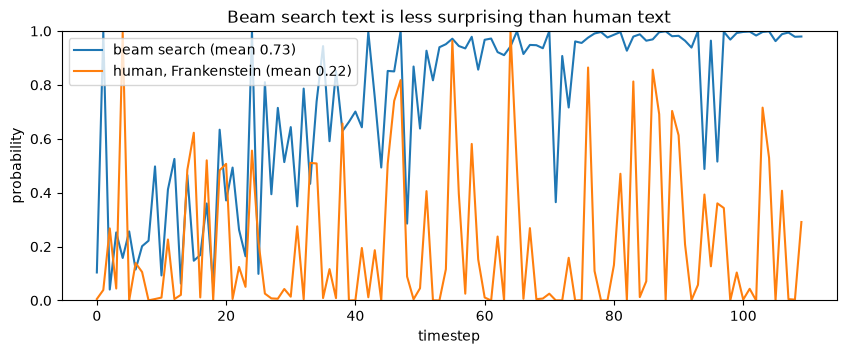

In [18]:
# ✅ Check your probabilities
assert human_probs.shape == (n,) and beam_probs.shape == (n,), "expected one probability per token, for both continuations"
assert ((human_probs > 0) & (human_probs <= 1)).all() and ((beam_probs > 0) & (beam_probs <= 1)).all(), "these should be probabilities"
print("Looks good ✅")

plt.figure(figsize=(10, 3.5))
plt.plot(beam_probs.cpu(), color="tab:blue", label=f"beam search (mean {beam_probs.mean():.2f})")
plt.plot(human_probs.cpu(), color="tab:orange", label=f"human, Frankenstein (mean {human_probs.mean():.2f})")
plt.xlabel("timestep")
plt.ylabel("probability")
plt.ylim(0, 1)
plt.legend()
plt.title("Beam search text is less surprising than human text")
plt.show()

**5.2 Compare your plot with the figure.** What does human text look like through the eyes of the model, compared with beam search? Based on this, is beam search a good strategy for open-ended text generation? What should a decoding strategy do instead?

---

*Answer:*

The plot looks like the figure: the beam-search tokens have high probabilities almost everywhere (and they tend to get *higher* over time, as the text starts repeating itself, which makes every next token more predictable). Human text jumps up and down: many tokens are predictable, but every few tokens there is one the model considered unlikely, a word choice that carries information.

High-quality human language does **not** consist of the most probable next words. We write text to say something the reader does not already know, so it has to surprise them now and then; text without surprises is boring and repetitive. Beam search (and greedy search) *maximise* probability, so they produce text that is unlike human text, however fluent. For open-ended generation they are not a viable strategy. A decoding strategy should instead produce text whose probabilities look like those of human text: mostly likely tokens, with occasional less likely ones. **Sampling** does exactly that.

---

## 6. Sampling

**Sampling** draws the next token at random from the model's distribution:

$$w_t \sim P(w \mid w_{1:t-1})$$

<center><img src="./assets/sampling_search.png"/></center>

After "The", "nice" (0.5) is chosen half of the time, "dog" (0.4) in 40% of the cases and "car" (0.1) in 10%. Sampling is **non-deterministic**, so we fix the random seed with `set_seed` to get reproducible results.

**6.1 Generate with pure sampling.** Set `do_sample=True` and switch off top-k sampling, which `generate` may apply by default, with `top_k=0` (more on top-k below).

In [19]:
set_seed(42)
sampled = generate_ids(PROMPT, max_new_tokens=40, do_sample=True, top_k=0)
report(*sampled)

I enjoy walking with my cute dog| in Plain Disposable Wood Ring Office boxes, counting calories and fixing the airline lockers!

Let me know if you're interested in purchasing this item. [40, May 1998]<|endoftext|>
-> average log-prob per token -4.34, distinct-2 1.00


In [26]:
# ✅ Check that you sampled
set_seed(1)
again = generate_ids(PROMPT, max_new_tokens=40, do_sample=True, top_k=0)
assert not torch.equal(sampled[1], greedy[1]), "the sampled text should differ from the greedy one. Did you set do_sample=True?"
assert not torch.equal(sampled[1], again[1]), "with another seed, sampling should give another text"
print("Looks good ✅")

Looks good ✅


The repetition is gone, but the text tends to be **incoherent**: it jumps between topics and sometimes includes words that make no sense. Every token of the vocabulary has *some* probability, and over 40 steps the long tail of unlikely tokens gets sampled now and then. One bad token is enough to derail the rest of the text.

### Temperature

As in week 6, the **temperature** $T$ reshapes the distribution before sampling:

$$P_T(w) = \text{softmax}\left(\frac{\text{logits}}{T}\right)$$

$T < 1$ makes it **sharper** (likely tokens become more likely), $T > 1$ makes it **flatter**. $T \to 0$ is greedy decoding.

<center><img src="./assets/sampling_search_with_temp.png"/></center>

The cell below shows the effect on GPT-2's next-token distribution after the prompt:

In [21]:
with torch.no_grad():
    logits = model(**tokenizer(PROMPT, return_tensors="pt").to(device)).logits[0, -1]
top = logits.topk(8).indices
for T in [0.5, 1.0, 1.5]:
    probs = F.softmax(logits / T, dim=-1)
    shown = ", ".join(f"{tokenizer.decode(i)!r} {probs[i]:.2f}" for i in top)
    print(f"T = {T}: {shown}   (top-8 mass {probs[top].sum():.2f})")

T = 0.5: ',' 0.51, '.' 0.25, ' and' 0.20, ',"' 0.01, ' in' 0.01, ' on' 0.00, ' (' 0.00, '."' 0.00   (top-8 mass 0.99)
T = 1.0: ',' 0.22, '.' 0.15, ' and' 0.14, ',"' 0.03, ' in' 0.03, ' on' 0.02, ' (' 0.01, '."' 0.01   (top-8 mass 0.61)
T = 1.5: ',' 0.04, '.' 0.04, ' and' 0.03, ',"' 0.01, ' in' 0.01, ' on' 0.01, ' (' 0.01, '."' 0.01   (top-8 mass 0.16)


**6.2 Generate with sampling at temperature 0.6** (still with `top_k=0`).

In [22]:
set_seed(42)
sampled_t = generate_ids(PROMPT, max_new_tokens=40, do_sample=True, top_k=0, temperature=0.6)
report(*sampled_t)

I enjoy walking with my cute dog|, so I want to have a lot of fun with her. We've been here for ages, and we've been going out for a few days now. It's been a great trip and I
-> average log-prob per token -1.95, distinct-2 1.00


### Top-k sampling

**Top-k sampling** ([Fan et al., 2018](https://arxiv.org/abs/1805.04833)) keeps only the $k$ most likely tokens, sets the probability of all others to zero, renormalises, and samples from what is left. GPT-2's authors used it with $k = 40$ ([Radford et al., 2019](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)). You implemented it for the mini GPT in week 6.

<center><img width=1000 src="./assets/top_k_sampling.png"/></center>

In the figure, $k = 6$: after "The" the six most likely words cover 68% of the probability mass, after "The car" they cover 99%.

**6.3 Generate with top-k sampling** with $k = 50$.

In [23]:
set_seed(42)
sampled_k = generate_ids(PROMPT, max_new_tokens=40, do_sample=True, top_k=50)
report(*sampled_k)

I enjoy walking with my cute dog| in my own space. I'm a loving wife, mom and grandmother. The two of us grew up together in a small space, and I'm very happy that there is a community in our home
-> average log-prob per token -2.51, distinct-2 1.00


**6.4 What are your takeaways on top-k sampling?** Look at the figure again: can you see a limitation of using the same $k$ at every step?

---

*Answer:*

Top-k removes the long tail of unlikely tokens, which removes most of the nonsense of pure sampling while keeping the variety. Combined with a temperature it gives fine control over the trade-off between coherence and diversity.

Its limitation is that $k$ is **fixed**, regardless of the shape of the distribution:
- When the distribution is **flat** (after "The", many words are plausible), top-k cuts off reasonable candidates ("people", "big", "house", "cat" in the figure), which limits creativity.
- When the distribution is **sharp** (after "The car", only "drives", "is" and "turns" make sense), the same $k$ still lets in unlikely words such as "down" or "a", which can lead to gibberish.

A good $k$ for one step is a bad one for the next.

---

### Top-p (nucleus) sampling

**Top-p sampling**, or **nucleus sampling** ([Holtzman et al., 2020](https://arxiv.org/abs/1904.09751), the same paper as the figure in Part 5), keeps the *smallest* set of most likely tokens whose probabilities add up to at least $p$. The number of candidates now adapts to the distribution: few when the model is sure, many when it is not.

<center><img width=1000 src="./assets/top_p_sampling.png"/></center>

With $p = 0.92$: after "The" the nucleus has 9 words (they cover 94%), after "The car" only 3 (97%).

**6.5 Measure the size of the nucleus.** Complete `nucleus_size`, which returns how many tokens top-p sampling keeps for the next token after a prompt.

Hints:
- Sort the probabilities in descending order (`torch.sort(probs, descending=True)`) and compute the cumulative sums with `torch.cumsum`.
- The nucleus contains all tokens up to and including the first one at which the cumulative sum reaches $p$.

In [24]:
@torch.no_grad()
def nucleus_size(prompt, p):
    # The number of tokens that top-p sampling with this p keeps for the next token after the prompt
    logits = model(**tokenizer(prompt, return_tensors="pt").to(device)).logits[0, -1]
    probs = F.softmax(logits, dim=-1)
    cumulative = torch.cumsum(torch.sort(probs, descending=True).values, dim=0)
    return int((cumulative < p).sum()) + 1


for prompt in ["The Eiffel Tower is located in the city of", "The car", "The", "My favourite thing to do on a Sunday is"]:
    print(f"{prompt!r:45}  p=0.5: {nucleus_size(prompt, 0.5):>5}   p=0.92: {nucleus_size(prompt, 0.92):>5}")

'The Eiffel Tower is located in the city of'   p=0.5:    52   p=0.92:  1183
'The car'                                      p=0.5:     9   p=0.92:   823
'The'                                          p=0.5:   998   p=0.92: 17151
'My favourite thing to do on a Sunday is'      p=0.5:     9   p=0.92:   650


In [27]:
# ✅ Check nucleus_size
assert nucleus_size("The", 1e-6) == 1, "a tiny p keeps only the most likely token"
assert nucleus_size("The", 0.5) <= nucleus_size("The", 0.92), "a larger p keeps more tokens"
assert nucleus_size("The Eiffel Tower is located in the city of", 0.92) < nucleus_size("My favourite thing to do on a Sunday is", 0.92), \
    "the model is much more certain about the Eiffel Tower than about Sundays"
print("Looks good ✅")

AssertionError: the model is much more certain about the Eiffel Tower than about Sundays

**6.6 Generate with top-p sampling** with $p = 0.92$, and top-k switched off.

In [ ]:
set_seed(42)
sampled_p = generate_ids(PROMPT, max_new_tokens=40, do_sample=True, top_p=0.92, top_k=0)
report(*sampled_p)

Top-p and top-k can also be combined: then a token has to be in both sets. In practice, top-p (often 0.9–0.95) together with a temperature (0.6–1.0) is the most common choice for open-ended text, and it is what many chat interfaces use.

## 7. All strategies side by side

**7.1 Complete `STRATEGIES`**, a dictionary from the name of each strategy to the arguments for `generate`. The cell after it generates 40 tokens for 5 prompts with every strategy and reports the averages of our two numbers. (This takes one to two minutes on a CPU.)

In [ ]:
STRATEGIES = {
    "greedy": {},
    "beam (5)": {"num_beams": 5, "early_stopping": True},
    "beam (5) + no-repeat 2": {"num_beams": 5, "early_stopping": True, "no_repeat_ngram_size": 2},
    "pure sampling": {"do_sample": True, "top_k": 0},
    "sampling, T=0.6": {"do_sample": True, "top_k": 0, "temperature": 0.6},
    "top-k (50)": {"do_sample": True, "top_k": 50},
    "top-p (0.92)": {"do_sample": True, "top_k": 0, "top_p": 0.92},
    "top-p (0.92), T=0.8": {"do_sample": True, "top_k": 0, "top_p": 0.92, "temperature": 0.8},
}

In [ ]:
# ✅ Check your strategies
assert all(isinstance(kwargs, dict) for kwargs in STRATEGIES.values()), "every strategy should be a dictionary of generate arguments"
for name, kwargs in STRATEGIES.items():
    assert kwargs.get("do_sample", False) == ("sampl" in name or "top-" in name), f"{name}: check do_sample"
    if name.startswith("beam"):
        assert kwargs.get("num_beams") == 5, f"{name}: use 5 beams"
assert STRATEGIES["top-p (0.92)"].get("top_k") == 0, "switch off top-k for top-p sampling"
print("Looks good ✅")

In [ ]:
PROMPTS = [
    "I enjoy walking with my cute dog",
    "The best way to learn a new language is",
    "In a shocking finding, scientists discovered a herd of unicorns",
    "The history of Aarhus begins",
    "She opened the letter and",
]

results, examples = {}, {}
for name, kwargs in STRATEGIES.items():
    set_seed(0)
    log_probs, distinct = [], []
    for prompt in PROMPTS:
        prompt_ids, new_ids = generate_ids(prompt, max_new_tokens=40, min_new_tokens=40, **kwargs)
        log_probs.append(token_log_probs(prompt_ids, new_ids).mean().item())
        distinct.append(distinct_n(tokenizer.decode(new_ids), 2))
        examples.setdefault(name, tokenizer.decode(new_ids))
    results[name] = (np.mean(log_probs), np.mean(distinct))

print(f"{'strategy':<26}{'avg log-prob':>14}{'distinct-2':>12}")
for name, (log_prob, distinct) in results.items():
    print(f"{name:<26}{log_prob:>14.2f}{distinct:>12.2f}")

In [ ]:
human_log_prob = token_log_probs(context_ids, human_continuation).mean().item()
human_distinct = distinct_n(tokenizer.decode(human_continuation), 2)

plt.figure(figsize=(7, 5))
for name, (log_prob, distinct) in results.items():
    plt.scatter(log_prob, distinct)
    plt.annotate(name, (log_prob, distinct), textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.scatter(human_log_prob, human_distinct, marker="*", s=200, color="black")
plt.annotate("human (Frankenstein)", (human_log_prob, human_distinct), textcoords="offset points", xytext=(5, -12), fontsize=8)
plt.xlabel("average log-probability per token (higher = more likely)")
plt.ylabel("distinct-2 (higher = less repetitive)")
plt.show()

for name, text in examples.items():
    print(f"===== {name} =====\n{PROMPTS[0]}|{text}\n")

**7.2 Describe the trade-off** that you see in the plot. Where does the human text lie? Which strategy would you choose for (a) machine translation, (b) writing a short story, (c) generating code, and (d) a chat assistant answering questions? Why?

---

*Answer:*

There is a clear **trade-off**: the deterministic, likelihood-maximising strategies (greedy, beam) have the *highest* log-probability but the *lowest* distinct-2: likely but repetitive. Pure sampling is at the other extreme: very diverse, but with a low log-probability, because it regularly picks tokens the model itself considers unlikely (that is where the incoherence comes from). The n-gram block raises diversity artificially without making the text less "safe". Temperature, top-k and top-p lie in between, and their parameters move them along the curve. The human text lies in between as well: diverse like sampled text, but with a log-probability between those of beam search and pure sampling. Top-p with a moderate temperature typically comes closest. (Strictly, the human point uses another context, so compare it only roughly.)

Choices:
- (a) **Translation**: beam search (4–5 beams). The output is tightly constrained by the source, there is essentially one right answer, and we want the most likely one.
- (b) **Story**: top-p sampling (e.g. $p = 0.9$–$0.95$) with a temperature around 0.7–1.0: diverse, surprising, but coherent.
- (c) **Code**: greedy or low-temperature sampling: code must be correct, and the most likely continuation usually is. (To produce several candidates and test them, sampling at a moderate temperature is useful.)
- (d) **Chat assistant**: usually top-p with a low-to-moderate temperature: answers should be correct and consistent, but not robotic or repetitive. For factual questions or evaluations, temperature 0 (greedy), as in week 7.

---

## 8. MCQ

Answer each question by writing the letter of your choice (A–D) after **Answer:**.

---

### 8.1. Greedy vs. beam search

Which statement about greedy search and beam search is correct?

A. Greedy search always finds the most likely sequence<br>
B. Beam search with `num_beams=1` is the same as greedy search<br>
C. Beam search always produces more diverse text than greedy search<br>
D. Beam search samples the next token from the top `num_beams` tokens<br>

**Answer:** **B**

With one beam, beam search keeps the single best sequence at every step, which is exactly greedy search. Neither of them is guaranteed to find the most likely sequence (A), beam search is deterministic (D), and its beams are usually very similar to each other (C).

---

### 8.2. Temperature

What happens when you sample with a temperature close to 0?

A. The output becomes completely random<br>
B. The output approaches greedy decoding<br>
C. The model ignores the prompt<br>
D. Only tokens with probability below 0.5 can be sampled<br>

**Answer:** **B**

Dividing the logits by a tiny temperature makes the largest logit dominate the softmax, so almost all the probability goes to the most likely token: sampling becomes greedy decoding. A high temperature flattens the distribution towards random (A).

---

### 8.3. Top-k vs. top-p

What is the main advantage of top-p (nucleus) sampling over top-k sampling?

A. It is deterministic<br>
B. It never samples tokens with a probability below $p$<br>
C. The number of candidate tokens adapts to the shape of the distribution<br>
D. It needs fewer forward passes<br>

**Answer:** **C**

Top-p keeps the smallest set of tokens with a total probability of at least $p$: few tokens when the model is sure, many when it is not. Top-k keeps the same $k$ every time. $p$ is a threshold on the *cumulative* probability, not on single tokens (B).

---

### 8.4. Human text

Holtzman et al. (2020) compared the probabilities that a language model assigns to human text and to beam-search output. What did they find?

A. Human text has higher token probabilities than beam-search text<br>
B. Human text has lower and much more variable token probabilities than beam-search text<br>
C. Both have the same distribution of token probabilities<br>
D. Beam-search text has more surprising tokens than human text<br>

**Answer:** **B**

Human text is not made of the most probable words: it regularly contains tokens the model considered unlikely. Beam search maximises probability and produces unnaturally predictable text, often with repetition. This motivated sampling methods such as nucleus sampling.

---

### 8.5. Choosing a strategy

For which task is beam search the most suitable decoding strategy?

A. Writing creative short stories<br>
B. Brainstorming many different product names<br>
C. Translating sentences from English to French<br>
D. Generating diverse dialogue for characters in a game<br>

**Answer:** **C**

Translation has (nearly) one right output for each input, and we want the most likely one: that is what beam search searches for. The other tasks need diversity and surprise, which calls for sampling.